# CSE465 — PVTv2-B0 + RetinaNet (No Augmentation)

Lightweight Transformer object-detection baseline for the prepared PV-cell defect dataset.

**Architecture**
- PVTv2-B0 backbone from `timm`
- ImageNet-1K pretrained backbone
- FPN from the last three PVTv2 stages (approximately strides 8, 16, 32)
- RetinaNet detection head
- 9 PV-defect classes

**Training**
- Input size: 640 × 640
- Physical batch size: 8
- Gradient accumulation: 2
- Effective batch size: 16
- Maximum epochs: 50
- Early-stopping patience: 5
- AMP enabled
- Seed: 42
- **No data augmentation**

Only deterministic letterbox resizing/padding is used. Letterboxing is preprocessing, not augmentation.

Notebook:
`MyDrive/Colab Notebooks/CSE465/04_PVTv2B0_RetinaNet_NoAug.ipynb`

Results:
`MyDrive/Study Materials /CSE465/04_PVTv2B0_RetinaNet_NoAug/`

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Install dependencies

In [2]:
!pip install -q timm torchmetrics pycocotools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 21.1 MB/s eta 0:00:00


## 3. Imports and reproducibility

In [3]:
import os
import gc
import cv2
import time
import yaml
import random
import shutil
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import OrderedDict, defaultdict

import torch
import torchvision
import timm

from torch import nn
from torch.utils.data import Dataset, DataLoader

from torchvision.models.detection.retinanet import RetinaNet
from torchvision.ops import FeaturePyramidNetwork, box_iou
from torchvision.ops.feature_pyramid_network import LastLevelP6P7

from torchmetrics.detection.mean_ap import MeanAveragePrecision

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if DEVICE.type != "cuda":
    raise RuntimeError(
        "GPU is required. In Colab choose Runtime > Change runtime type > T4 GPU."
    )

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
timm: 1.0.28
GPU: Tesla T4


## 4. Drive folders

In [4]:
CSE_ROOT = Path("/content/drive/MyDrive/Study Materials /CSE465")
DATA_ZIP = CSE_ROOT / "Prepared Dataset.zip"

EXP_ROOT = CSE_ROOT / "04_PVTv2B0_RetinaNet_NoAug"
WEIGHTS_DIR = EXP_ROOT / "weights"
METRICS_DIR = EXP_ROOT / "metrics"
PLOTS_DIR = EXP_ROOT / "plots"
PREDICTIONS_DIR = EXP_ROOT / "predictions"
CONFIG_DIR = EXP_ROOT / "config"

for folder in [
    EXP_ROOT,
    WEIGHTS_DIR,
    METRICS_DIR,
    PLOTS_DIR,
    PREDICTIONS_DIR,
    CONFIG_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

BEST_PT = WEIGHTS_DIR / "best.pt"
LAST_PT = WEIGHTS_DIR / "last.pt"

assert DATA_ZIP.exists(), f"Dataset ZIP not found: {DATA_ZIP}"

print("Dataset:", DATA_ZIP)
print("Experiment:", EXP_ROOT)

Dataset: /content/drive/MyDrive/Study Materials /CSE465/Prepared Dataset.zip
Experiment: /content/drive/MyDrive/Study Materials /CSE465/04_PVTv2B0_RetinaNet_NoAug


## 5. Extract prepared dataset locally

In [5]:
LOCAL_ROOT = Path("/content/CSE465_dataset")

if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(DATA_ZIP, "r") as z:
    z.extractall(LOCAL_ROOT)

DATASET_DIR = LOCAL_ROOT / "Prepared Dataset"
DATA_YAML = DATASET_DIR / "data.yaml"

assert DATASET_DIR.exists()
assert DATA_YAML.exists()

print("Dataset extracted to:", DATASET_DIR)

Dataset extracted to: /content/CSE465_dataset/Prepared Dataset


## 6. Read dataset configuration

In [6]:
with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)

CLASS_NAMES = data_config["names"]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", CLASS_NAMES)
print("Number of detection classes:", NUM_CLASSES)

for split in ["train", "val", "test"]:
    n_img = len(list((DATASET_DIR / "images" / split).glob("*")))
    n_lbl = len(list((DATASET_DIR / "labels" / split).glob("*.txt")))
    print(f"{split:5s}: {n_img} images | {n_lbl} labels")

Classes: ['finger', 'crack', 'black_core', 'thick_line', 'horizontal_dislocation', 'short_circuit', 'vertical_dislocation', 'star_crack', 'printing_error']
Number of detection classes: 9
train: 4418 images | 4418 labels
val  : 947 images | 947 labels
test : 949 images | 949 labels


## 7. Training configuration

Start with physical batch **8** on a Colab T4 because PVTv2-B0 is substantially lighter than Swin-T.

If the first training batch gives CUDA OOM, change:
- `BATCH_SIZE = 4`
- `ACCUM_STEPS = 4`

The effective batch remains 16.

In [7]:
IMAGE_SIZE = 640

BATCH_SIZE = 8
ACCUM_STEPS = 2
EFFECTIVE_BATCH = BATCH_SIZE * ACCUM_STEPS

MAX_EPOCHS = 50
PATIENCE = 5
NUM_WORKERS = 2

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 0.05
GRAD_CLIP = 1.0

AMP = True

CONF_THRESHOLD = 0.25
MATCH_IOU_THRESHOLD = 0.50

RESUME = False  # Change to True only after a disconnect/restart.

training_config = {
    "model": "PVTv2-B0 + FPN + RetinaNet",
    "experiment": "NoAug",
    "image_size": IMAGE_SIZE,
    "physical_batch_size": BATCH_SIZE,
    "gradient_accumulation": ACCUM_STEPS,
    "effective_batch_size": EFFECTIVE_BATCH,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "seed": SEED,
    "augmentation": "None",
    "backbone_pretraining": "ImageNet-1K",
    "detections_per_image": 100,
}

with open(CONFIG_DIR / "training_config.yaml", "w") as f:
    yaml.safe_dump(training_config, f, sort_keys=False)

print(training_config)

{'model': 'PVTv2-B0 + FPN + RetinaNet', 'experiment': 'NoAug', 'image_size': 640, 'physical_batch_size': 8, 'gradient_accumulation': 2, 'effective_batch_size': 16, 'max_epochs': 50, 'patience': 5, 'learning_rate': 0.0001, 'weight_decay': 0.05, 'seed': 42, 'augmentation': 'None', 'backbone_pretraining': 'ImageNet-1K', 'detections_per_image': 100}


## 8. Dataset class — deterministic preprocessing only

This performs:
1. image loading,
2. deterministic letterbox resize/padding to 640×640,
3. YOLO-label conversion to `[x1, y1, x2, y2]`,
4. tensor conversion.

There are **no random flips, rotations, color transforms, Mosaic, MixUp, CutMix, or other augmentations**.

In [8]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def letterbox_image(image, boxes, size=640, fill=114):
    h, w = image.shape[:2]

    scale = min(size / w, size / h)

    new_w = int(round(w * scale))
    new_h = int(round(h * scale))

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_LINEAR,
    )

    pad_x = (size - new_w) // 2
    pad_y = (size - new_h) // 2

    canvas = np.full(
        (size, size, 3),
        fill,
        dtype=np.uint8,
    )

    canvas[
        pad_y:pad_y + new_h,
        pad_x:pad_x + new_w,
    ] = resized

    if len(boxes):
        boxes = boxes.copy().astype(np.float32)

        boxes[:, [0, 2]] = (
            boxes[:, [0, 2]] * scale + pad_x
        )

        boxes[:, [1, 3]] = (
            boxes[:, [1, 3]] * scale + pad_y
        )

    return canvas, boxes


class PVDetectionDataset(Dataset):
    def __init__(self, dataset_dir, split, image_size=640):
        self.image_dir = Path(dataset_dir) / "images" / split
        self.label_dir = Path(dataset_dir) / "labels" / split
        self.image_size = image_size

        self.images = sorted(
            p for p in self.image_dir.iterdir()
            if p.suffix.lower() in IMAGE_EXTENSIONS
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_path = self.images[idx]
        label_path = self.label_dir / f"{image_path.stem}.txt"

        image = cv2.imread(str(image_path))

        if image is None:
            raise RuntimeError(f"Could not read: {image_path}")

        image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB,
        )

        h, w = image.shape[:2]

        boxes = []
        labels = []

        if label_path.exists():
            text = label_path.read_text().strip()

            if text:
                for line in text.splitlines():
                    cls_id, xc, yc, bw, bh = map(
                        float,
                        line.split(),
                    )

                    x1 = (xc - bw / 2) * w
                    y1 = (yc - bh / 2) * h
                    x2 = (xc + bw / 2) * w
                    y2 = (yc + bh / 2) * h

                    boxes.append([x1, y1, x2, y2])
                    labels.append(int(cls_id))

        boxes = np.asarray(
            boxes,
            dtype=np.float32,
        ).reshape(-1, 4)

        image, boxes = letterbox_image(
            image,
            boxes,
            size=self.image_size,
        )

        image = (
            torch.from_numpy(image)
            .permute(2, 0, 1)
            .float()
            / 255.0
        )

        target = {
            "boxes": torch.as_tensor(
                boxes,
                dtype=torch.float32,
            ),
            "labels": torch.as_tensor(
                labels,
                dtype=torch.int64,
            ),
            "image_id": torch.tensor(
                [idx],
                dtype=torch.int64,
            ),
        }

        return image, target, str(image_path)


def collate_fn(batch):
    images, targets, paths = zip(*batch)

    return (
        list(images),
        list(targets),
        list(paths),
    )


train_dataset = PVDetectionDataset(
    DATASET_DIR,
    "train",
    IMAGE_SIZE,
)

val_dataset = PVDetectionDataset(
    DATASET_DIR,
    "val",
    IMAGE_SIZE,
)

test_dataset = PVDetectionDataset(
    DATASET_DIR,
    "test",
    IMAGE_SIZE,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    collate_fn=collate_fn,
)

print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))
print("Physical batch:", BATCH_SIZE)
print("Effective batch:", EFFECTIVE_BATCH)

Train: 4418
Val  : 947
Test : 949
Physical batch: 8
Effective batch: 16


## 9. Build PVTv2-B0 + FPN + RetinaNet

`timm` supplies the pretrained PVTv2-B0 backbone in feature-extraction mode.

The last three hierarchical feature stages are sent to an FPN, followed by a RetinaNet detection head.

The code reads the feature-channel dimensions directly from `timm` instead of hard-coding them.

In [9]:
class PVTv2B0FPN(nn.Module):
    def __init__(self, pretrained=True, out_channels=256):
        super().__init__()

        self.body = timm.create_model(
            "pvt_v2_b0",
            pretrained=pretrained,
            features_only=True,
            out_indices=(1, 2, 3),
        )

        feature_channels = self.body.feature_info.channels()
        feature_reductions = self.body.feature_info.reduction()

        print("PVTv2 feature channels:", feature_channels)
        print("PVTv2 feature strides :", feature_reductions)

        self.fpn = FeaturePyramidNetwork(
            in_channels_list=feature_channels,
            out_channels=out_channels,
            extra_blocks=LastLevelP6P7(
                feature_channels[-1],
                out_channels,
            ),
        )

        self.out_channels = out_channels

    def forward(self, x):
        features = self.body(x)

        features = OrderedDict(
            (str(i), feat)
            for i, feat in enumerate(features)
        )

        return self.fpn(features)


def build_model():
    backbone = PVTv2B0FPN(
        pretrained=True,
        out_channels=256,
    )

    model = RetinaNet(
        backbone=backbone,
        num_classes=NUM_CLASSES,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        image_mean=[0.485, 0.456, 0.406],
        image_std=[0.229, 0.224, 0.225],
        score_thresh=0.001,
        detections_per_img=100,
    )

    return model


model = build_model().to(DEVICE)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Total parameters    : "
    f"{total_params:,} ({total_params/1e6:.3f} M)"
)

print(
    f"Trainable parameters: "
    f"{trainable_params:,} ({trainable_params/1e6:.3f} M)"
)

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.7MB            

model.safetensors: downloading bytes:           |  0.00B            

PVTv2 feature channels: [64, 160, 256]
PVTv2 feature strides : [8, 16, 32]
Total parameters    : 11,474,133 (11.474 M)
Trainable parameters: 11,474,133 (11.474 M)


## 10. Optimizer, scheduler and AMP

To keep the comparison with the Swin-T baseline consistent:
- AdamW
- learning rate = `1e-4`
- weight decay = `0.05`
- cosine LR schedule
- AMP
- effective batch = 16

In [10]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=1e-6,
)

try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=AMP,
    )
except TypeError:
    scaler = torch.cuda.amp.GradScaler(
        enabled=AMP,
    )


def autocast_context():
    try:
        return torch.amp.autocast(
            "cuda",
            enabled=AMP,
        )
    except TypeError:
        return torch.cuda.amp.autocast(
            enabled=AMP,
        )


print("Optimizer: AdamW")
print("AMP:", AMP)

Optimizer: AdamW
AMP: True


## 11. Validation helpers

In [11]:
def move_targets_to_device(targets):
    return [
        {
            k: v.to(
                DEVICE,
                non_blocking=True,
            )
            for k, v in t.items()
        }
        for t in targets
    ]


@torch.no_grad()
def compute_validation_loss(model, loader):
    # Torchvision detection models return losses in train mode.
    # PVTv2-B0 in timm has no random augmentation here;
    # gradients remain disabled by @torch.no_grad().
    model.train()

    total_cls = 0.0
    total_box = 0.0
    total_images = 0

    start = time.perf_counter()

    for images, targets, _ in loader:
        images = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        targets = move_targets_to_device(targets)

        with autocast_context():
            losses = model(
                images,
                targets,
            )

        batch_n = len(images)

        total_cls += (
            float(
                losses["classification"].detach()
            )
            * batch_n
        )

        total_box += (
            float(
                losses["bbox_regression"].detach()
            )
            * batch_n
        )

        total_images += batch_n

    torch.cuda.synchronize()

    seconds = (
        time.perf_counter()
        - start
    )

    model.eval()

    cls_loss = (
        total_cls
        / max(total_images, 1)
    )

    box_loss = (
        total_box
        / max(total_images, 1)
    )

    return {
        "classification_loss": cls_loss,
        "bbox_regression_loss": box_loss,
        "total_loss": cls_loss + box_loss,
        "seconds": seconds,
    }


@torch.no_grad()
def evaluate_map(model, loader):
    model.eval()

    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=False,
    )

    start = time.perf_counter()

    for images, targets, _ in loader:
        images_gpu = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        with autocast_context():
            outputs = model(images_gpu)

        preds = [
            {
                "boxes": out["boxes"].detach().cpu(),
                "scores": out["scores"].detach().cpu(),
                "labels": out["labels"].detach().cpu(),
            }
            for out in outputs
        ]

        gts = [
            {
                "boxes": t["boxes"].detach().cpu(),
                "labels": t["labels"].detach().cpu(),
            }
            for t in targets
        ]

        metric.update(preds, gts)

    torch.cuda.synchronize()

    seconds = (
        time.perf_counter()
        - start
    )

    result = metric.compute()

    return {
        "map50": float(result["map_50"]),
        "map75": float(result["map_75"]),
        "map50_95": float(result["map"]),
        "seconds": seconds,
    }

# Fresh Start or Resume

## 12. Resume support

For a fresh run:

```python
RESUME = False
```

After a Colab disconnect:
1. reconnect to a GPU,
2. rerun the setup/model/optimizer cells,
3. set `RESUME = True`,
4. rerun this cell and the training cell.

`last.pt` is overwritten each epoch.

In [12]:
history = []
start_epoch = 1

best_map = -1.0
best_epoch = 0
epochs_without_improvement = 0

if RESUME:
    if not LAST_PT.exists():
        raise FileNotFoundError(
            f"No resume checkpoint found: {LAST_PT}"
        )

    checkpoint = torch.load(
        LAST_PT,
        map_location=DEVICE,
    )

    model.load_state_dict(
        checkpoint["model_state"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state"]
    )

    if "scaler_state" in checkpoint:
        scaler.load_state_dict(
            checkpoint["scaler_state"]
        )

    start_epoch = (
        int(checkpoint["epoch"])
        + 1
    )

    best_map = float(
        checkpoint["best_map"]
    )

    best_epoch = int(
        checkpoint["best_epoch"]
    )

    epochs_without_improvement = int(
        checkpoint[
            "epochs_without_improvement"
        ]
    )

    history = checkpoint.get(
        "history",
        [],
    )

    print(
        f"Resuming from epoch "
        f"{start_epoch}"
    )

else:
    if LAST_PT.exists():
        raise RuntimeError(
            "Existing last.pt found. "
            "Set RESUME=True to continue, "
            "or delete/use a new experiment folder "
            "for a fresh run."
        )

    print(
        "Starting a fresh "
        "PVTv2-B0 + RetinaNet run."
    )

Starting a fresh PVTv2-B0 + RetinaNet run.


## 13. Train — live epoch/batch progress

The model is selected using validation **mAP@50-95**.

Early stopping:
- maximum = 50 epochs
- patience = 5

The live progress bar shows current batch loss and VRAM.

In [13]:
from tqdm.auto import tqdm

for epoch in range(
    start_epoch,
    MAX_EPOCHS + 1,
):

    model.train()

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    epoch_start = time.perf_counter()

    train_cls_sum = 0.0
    train_box_sum = 0.0
    train_images = 0

    optimizer.zero_grad(
        set_to_none=True
    )

    n_steps = len(train_loader)

    train_bar = tqdm(
        enumerate(train_loader),
        total=n_steps,
        desc=f"Epoch {epoch}/{MAX_EPOCHS}",
        dynamic_ncols=True,
    )

    for step, (
        images,
        targets,
        _,
    ) in train_bar:

        images = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        targets = move_targets_to_device(
            targets
        )

        group_start = (
            step // ACCUM_STEPS
        ) * ACCUM_STEPS

        group_end = min(
            group_start + ACCUM_STEPS,
            n_steps,
        )

        group_size = (
            group_end - group_start
        )

        with autocast_context():
            losses = model(
                images,
                targets,
            )

            cls_loss = losses[
                "classification"
            ]

            box_loss = losses[
                "bbox_regression"
            ]

            total_loss = (
                cls_loss + box_loss
            )

            scaled_loss = (
                total_loss
                / group_size
            )

        scaler.scale(
            scaled_loss
        ).backward()

        if step == group_end - 1:
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP,
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )

        batch_n = len(images)

        train_cls_sum += (
            float(cls_loss.detach())
            * batch_n
        )

        train_box_sum += (
            float(box_loss.detach())
            * batch_n
        )

        train_images += batch_n

        train_bar.set_postfix({
            "loss": (
                f"{float(total_loss.detach()):.4f}"
            ),
            "cls": (
                f"{float(cls_loss.detach()):.4f}"
            ),
            "box": (
                f"{float(box_loss.detach()):.4f}"
            ),
            "VRAM": (
                f"{torch.cuda.memory_allocated()/1024**3:.1f}G"
            ),
        })

    torch.cuda.synchronize()

    train_seconds = (
        time.perf_counter()
        - epoch_start
    )

    train_cls = (
        train_cls_sum
        / train_images
    )

    train_box = (
        train_box_sum
        / train_images
    )

    train_total = (
        train_cls + train_box
    )

    print(
        "\nCalculating validation loss..."
    )

    val_loss_result = (
        compute_validation_loss(
            model,
            val_loader,
        )
    )

    print(
        "Calculating validation mAP..."
    )

    val_map_result = evaluate_map(
        model,
        val_loader,
    )

    scheduler.step()

    total_seconds = (
        train_seconds
        + val_loss_result["seconds"]
        + val_map_result["seconds"]
    )

    peak_vram_gb = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    record = {
        "epoch": epoch,

        "train/classification_loss":
            train_cls,

        "train/bbox_regression_loss":
            train_box,

        "train/total_loss":
            train_total,

        "val/classification_loss":
            val_loss_result[
                "classification_loss"
            ],

        "val/bbox_regression_loss":
            val_loss_result[
                "bbox_regression_loss"
            ],

        "val/total_loss":
            val_loss_result[
                "total_loss"
            ],

        "val/mAP50":
            val_map_result["map50"],

        "val/mAP75":
            val_map_result["map75"],

        "val/mAP50-95":
            val_map_result["map50_95"],

        "train_seconds":
            train_seconds,

        "val_loss_seconds":
            val_loss_result["seconds"],

        "val_map_seconds":
            val_map_result["seconds"],

        "total_seconds":
            total_seconds,

        "lr":
            optimizer.param_groups[0]["lr"],

        "peak_vram_GB":
            peak_vram_gb,
    }

    history.append(record)

    history_df = pd.DataFrame(
        history
    )

    history_df.to_csv(
        METRICS_DIR
        / "training_history.csv",
        index=False,
    )

    current_map = (
        val_map_result["map50_95"]
    )

    improved = (
        current_map > best_map
    )

    if improved:
        best_map = current_map
        best_epoch = epoch

        epochs_without_improvement = 0

        best_state = {
            "epoch": epoch,
            "best_map50_95": best_map,

            "model_state": {
                k: v.detach().cpu()
                for k, v
                in model.state_dict().items()
            },

            "class_names": CLASS_NAMES,
            "training_config":
                training_config,
        }

        torch.save(
            best_state,
            BEST_PT,
        )

    else:
        epochs_without_improvement += 1

    last_state = {
        "epoch": epoch,

        "model_state":
            model.state_dict(),

        "optimizer_state":
            optimizer.state_dict(),

        "scheduler_state":
            scheduler.state_dict(),

        "scaler_state":
            scaler.state_dict(),

        "best_map":
            best_map,

        "best_epoch":
            best_epoch,

        "epochs_without_improvement":
            epochs_without_improvement,

        "history":
            history,

        "training_config":
            training_config,
    }

    torch.save(
        last_state,
        LAST_PT,
    )

    print(
        "\n"
        + "=" * 70
    )

    print(
        f"EPOCH {epoch}/{MAX_EPOCHS} COMPLETE"
    )

    print("-" * 70)

    print(
        f"Train Loss    : "
        f"{train_total:.4f} "
        f"(Cls {train_cls:.4f} | "
        f"Box {train_box:.4f})"
    )

    print(
        f"Val Loss      : "
        f"{val_loss_result['total_loss']:.4f}"
    )

    print(
        f"Val mAP@50    : "
        f"{val_map_result['map50']:.4f}"
    )

    print(
        f"Val mAP@75    : "
        f"{val_map_result['map75']:.4f}"
    )

    print(
        f"Val mAP@50-95 : "
        f"{current_map:.4f}"
    )

    print("-" * 70)

    print(
        f"Train time    : "
        f"{train_seconds/60:.2f} min"
    )

    print(
        f"Val-loss time : "
        f"{val_loss_result['seconds']/60:.2f} min"
    )

    print(
        f"Val-mAP time  : "
        f"{val_map_result['seconds']/60:.2f} min"
    )

    print(
        f"Total epoch   : "
        f"{total_seconds/60:.2f} min"
    )

    print(
        f"Peak VRAM     : "
        f"{peak_vram_gb:.2f} GB"
    )

    print("-" * 70)

    print(
        f"Best epoch    : "
        f"{best_epoch}"
    )

    print(
        f"Best mAP50-95 : "
        f"{best_map:.4f}"
    )

    print(
        f"Early stopping: "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    print("=" * 70)

    if (
        epochs_without_improvement
        >= PATIENCE
    ):
        print(
            f"\nEarly stopping triggered "
            f"at epoch {epoch}."
        )

        break

print("\nTRAINING FINISHED")
print("Best epoch:", best_epoch)

print(
    "Best validation mAP@50-95:",
    round(best_map, 4),
)

Epoch 1/50:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 1/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 1.0817 (Cls 0.5261 | Box 0.5556)
Val Loss      : 0.7458
Val mAP@50    : 0.3293
Val mAP@75    : 0.1551
Val mAP@50-95 : 0.1763
----------------------------------------------------------------------
Train time    : 3.04 min
Val-loss time : 0.33 min
Val-mAP time  : 0.40 min
Total epoch   : 3.77 min
Peak VRAM     : 2.43 GB
----------------------------------------------------------------------
Best epoch    : 1
Best mAP50-95 : 0.1763
Early stopping: 0/5


Epoch 2/50:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 2/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.6595 (Cls 0.3149 | Box 0.3446)
Val Loss      : 0.7760
Val mAP@50    : 0.4845
Val mAP@75    : 0.1885
Val mAP@50-95 : 0.2333
----------------------------------------------------------------------
Train time    : 2.93 min
Val-loss time : 0.30 min
Val-mAP time  : 0.41 min
Total epoch   : 3.65 min
Peak VRAM     : 2.44 GB
----------------------------------------------------------------------
Best epoch    : 2
Best mAP50-95 : 0.2333
Early stopping: 0/5


Epoch 3/50:   0%|          | 0/553 [00:00<?, ?it/s]

...


Calculating validation loss...
Calculating validation mAP...

EPOCH 24/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.1403 (Cls 0.0572 | Box 0.0831)
Val Loss      : 0.7110
Val mAP@50    : 0.8948
Val mAP@75    : 0.4757
Val mAP@50-95 : 0.5423
----------------------------------------------------------------------
Train time    : 2.94 min
Val-loss time : 0.31 min
Val-mAP time  : 0.39 min
Total epoch   : 3.64 min
Peak VRAM     : 2.44 GB
----------------------------------------------------------------------
Best epoch    : 21
Best mAP50-95 : 0.5769
Early stopping: 3/5


Epoch 25/50:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 25/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.1360 (Cls 0.0599 | Box 0.0761)
Val Loss      : 0.7276
Val mAP@50    : 0.8260
Val mAP@75    : 0.5243
Val mAP@50-95 : 0.5297
----------------------------------------------------------------------
Train time    : 2.93 min
Val-loss time : 0.31 min
Val-mAP time  : 0.40 min
Total epoch   : 3.65 min
Peak VRAM     : 2.44 GB
----------------------------------------------------------------------
Best epoch    : 21
Best mAP50-95 : 0.5769
Early stopping: 4/5


Epoch 26/50:   0%|          | 0/553 [00:00<?, ?it/s]


Calculating validation loss...
Calculating validation mAP...

EPOCH 26/50 COMPLETE
----------------------------------------------------------------------
Train Loss    : 0.1377 (Cls 0.0615 | Box 0.0761)
Val Loss      : 1.3884
Val mAP@50    : 0.8840
Val mAP@75    : 0.5322
Val mAP@50-95 : 0.5522
----------------------------------------------------------------------
Train time    : 2.91 min
Val-loss time : 0.31 min
Val-mAP time  : 0.40 min
Total epoch   : 3.62 min
Peak VRAM     : 2.44 GB
----------------------------------------------------------------------
Best epoch    : 21
Best mAP50-95 : 0.5769
Early stopping: 5/5

Early stopping triggered at epoch 26.

TRAINING FINISHED
Best epoch: 21
Best validation mAP@50-95: 0.5769


# Result

## 14. Training history and timing summary

In [14]:
history_df = pd.read_csv(
    METRICS_DIR
    / "training_history.csv"
)

epochs_completed = int(
    history_df["epoch"].max()
)

best_row = history_df.loc[
    history_df["val/mAP50-95"].idxmax()
]

best_epoch = int(
    best_row["epoch"]
)

timing_summary = pd.DataFrame([{
    "epochs_completed":
        epochs_completed,

    "best_epoch":
        best_epoch,

    "mean_train_min_per_epoch":
        history_df[
            "train_seconds"
        ].mean() / 60,

    "mean_val_loss_min_per_epoch":
        history_df[
            "val_loss_seconds"
        ].mean() / 60,

    "mean_val_map_min_per_epoch":
        history_df[
            "val_map_seconds"
        ].mean() / 60,

    "mean_total_min_per_epoch":
        history_df[
            "total_seconds"
        ].mean() / 60,

    "total_training_run_min":
        history_df[
            "total_seconds"
        ].sum() / 60,

    "mean_peak_vram_GB":
        history_df[
            "peak_vram_GB"
        ].mean(),

    "max_peak_vram_GB":
        history_df[
            "peak_vram_GB"
        ].max(),
}]).round(4)

timing_summary.to_csv(
    METRICS_DIR
    / "timing_summary.csv",
    index=False,
)

display(timing_summary)

,epochs_completed,best_epoch,mean_train_min_per_epoch,mean_val_loss_min_per_epoch,mean_val_map_min_per_epoch,mean_total_min_per_epoch,total_training_run_min,mean_peak_vram_GB,max_peak_vram_GB
0,26,21,2.9449,0.3116,0.4054,3.662,95.2107,2.4397,2.4424


## 15. Training vs validation loss curves

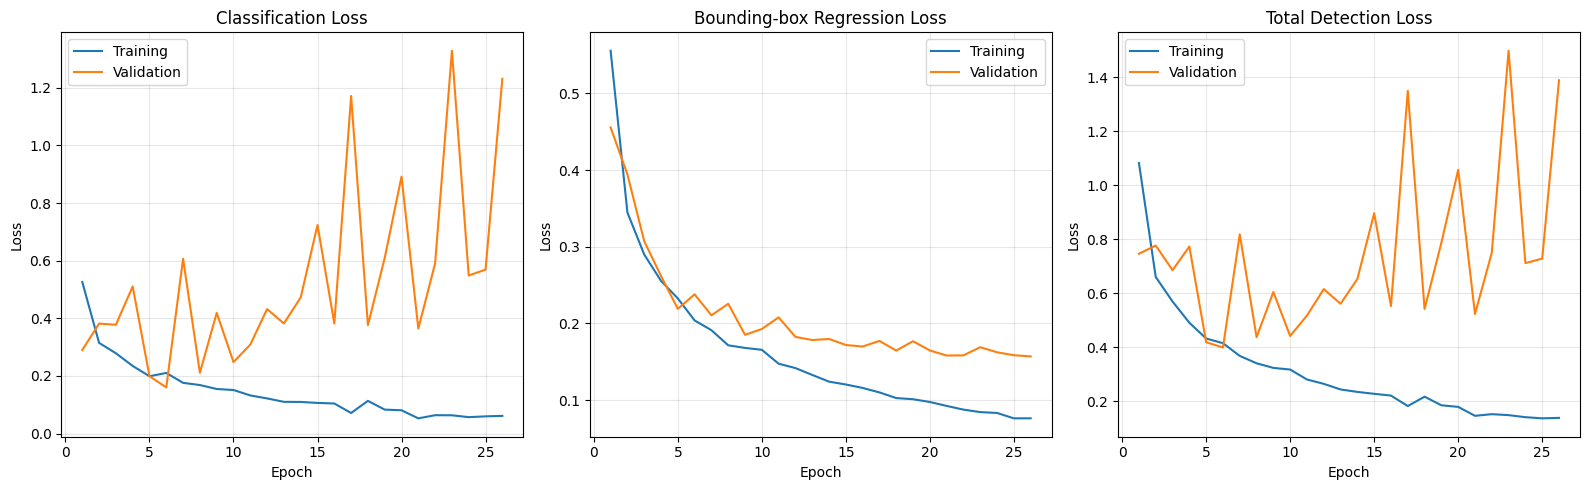

In [15]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5),
)

loss_pairs = [
    (
        "train/classification_loss",
        "val/classification_loss",
        "Classification Loss",
    ),
    (
        "train/bbox_regression_loss",
        "val/bbox_regression_loss",
        "Bounding-box Regression Loss",
    ),
    (
        "train/total_loss",
        "val/total_loss",
        "Total Detection Loss",
    ),
]

for ax, (
    train_col,
    val_col,
    title,
) in zip(
    axes,
    loss_pairs,
):
    ax.plot(
        history_df["epoch"],
        history_df[train_col],
        label="Training",
    )

    ax.plot(
        history_df["epoch"],
        history_df[val_col],
        label="Validation",
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "training_validation_loss_curves.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 16. Validation mAP vs epoch

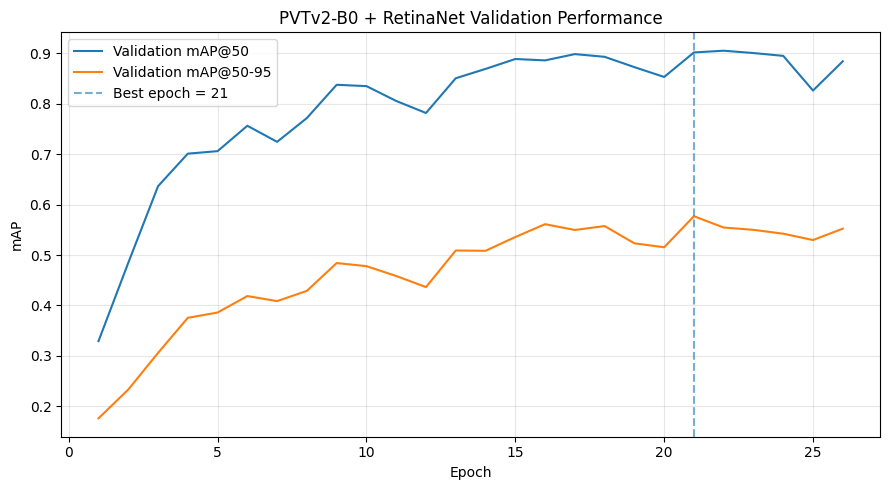

In [16]:
plt.figure(
    figsize=(9, 5)
)

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50"],
    label="Validation mAP@50",
)

plt.plot(
    history_df["epoch"],
    history_df["val/mAP50-95"],
    label="Validation mAP@50-95",
)

plt.axvline(
    best_epoch,
    linestyle="--",
    alpha=0.6,
    label=f"Best epoch = {best_epoch}",
)

plt.xlabel("Epoch")
plt.ylabel("mAP")

plt.title(
    "PVTv2-B0 + RetinaNet "
    "Validation Performance"
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "validation_map_vs_epoch.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 17. Load the best model for final test evaluation

In [17]:
best_checkpoint = torch.load(
    BEST_PT,
    map_location="cpu",
)

model.load_state_dict(
    best_checkpoint["model_state"]
)

model = model.to(DEVICE)
model.eval()

gc.collect()
torch.cuda.empty_cache()

print(
    f"Loaded best model from epoch "
    f"{best_checkpoint['epoch']} "
    f"(val mAP50-95="
    f"{best_checkpoint['best_map50_95']:.4f})"
)

Loaded best model from epoch 21 (val mAP50-95=0.5769)


## 18. Collect test predictions once

In [18]:
@torch.no_grad()
def collect_predictions(
    model,
    loader,
):
    model.eval()

    predictions = []
    targets_all = []
    paths_all = []

    total_forward_seconds = 0.0
    total_images = 0

    for images, targets, paths in loader:
        images_gpu = [
            img.to(
                DEVICE,
                non_blocking=True,
            )
            for img in images
        ]

        torch.cuda.synchronize()
        start = time.perf_counter()

        with autocast_context():
            outputs = model(
                images_gpu
            )

        torch.cuda.synchronize()

        total_forward_seconds += (
            time.perf_counter()
            - start
        )

        total_images += len(images)

        for out in outputs:
            predictions.append({
                "boxes":
                    out["boxes"].detach().cpu(),

                "scores":
                    out["scores"].detach().cpu(),

                "labels":
                    out["labels"].detach().cpu(),
            })

        for target in targets:
            targets_all.append({
                "boxes":
                    target["boxes"].detach().cpu(),

                "labels":
                    target["labels"].detach().cpu(),
            })

        paths_all.extend(paths)

    inference_ms = (
        total_forward_seconds
        / max(total_images, 1)
        * 1000
    )

    return (
        predictions,
        targets_all,
        paths_all,
        inference_ms,
    )


(
    test_predictions,
    test_targets,
    test_paths,
    inference_ms,
) = collect_predictions(
    model,
    test_loader,
)

fps = (
    1000 / inference_ms
    if inference_ms > 0
    else np.nan
)

print(
    "Test images:",
    len(test_predictions),
)

print(
    f"Model forward time: "
    f"{inference_ms:.3f} ms/image"
)

print(
    f"FPS: {fps:.2f}"
)

Test images: 949
Model forward time: 26.231 ms/image
FPS: 38.12


## 19. Test mAP50, mAP75 and mAP50–95

In [19]:
map_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
)

map50_metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    iou_thresholds=[0.50],
    class_metrics=True,
)

map_metric.update(
    test_predictions,
    test_targets,
)

map50_metric.update(
    test_predictions,
    test_targets,
)

map_result = (
    map_metric.compute()
)

map50_result = (
    map50_metric.compute()
)

test_map50 = float(
    map_result["map_50"]
)

test_map75 = float(
    map_result["map_75"]
)

test_map50_95 = float(
    map_result["map"]
)

print(
    f"mAP@50    : "
    f"{test_map50:.4f}"
)

print(
    f"mAP@75    : "
    f"{test_map75:.4f}"
)

print(
    f"mAP@50-95 : "
    f"{test_map50_95:.4f}"
)

mAP@50    : 0.8852
mAP@75    : 0.5471
mAP@50-95 : 0.5626


## 20. Precision, Recall, F1, matched box IoU and Dice

Threshold metrics:
- confidence ≥ 0.25
- class-aware one-to-one matching
- TP IoU threshold = 0.50

IoU and Dice are **bounding-box overlap metrics**, not segmentation-mask metrics.

In [20]:
def class_aware_matches(
    pred,
    gt,
    conf_threshold=0.25,
    iou_threshold=0.50,
):
    keep = (
        pred["scores"]
        >= conf_threshold
    )

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    if (
        len(p_boxes) == 0
        or len(g_boxes) == 0
    ):
        return (
            [],
            p_boxes,
            p_labels,
        )

    ious = box_iou(
        p_boxes,
        g_boxes,
    )

    candidates = []

    for pi in range(
        len(p_boxes)
    ):
        for gi in range(
            len(g_boxes)
        ):
            if (
                int(p_labels[pi])
                != int(g_labels[gi])
            ):
                continue

            iou = float(
                ious[pi, gi]
            )

            if (
                iou
                >= iou_threshold
            ):
                candidates.append(
                    (
                        iou,
                        pi,
                        gi,
                    )
                )

    candidates.sort(
        reverse=True
    )

    used_pred = set()
    used_gt = set()
    matches = []

    for iou, pi, gi in candidates:
        if (
            pi in used_pred
            or gi in used_gt
        ):
            continue

        used_pred.add(pi)
        used_gt.add(gi)

        matches.append(
            (
                pi,
                gi,
                iou,
            )
        )

    return (
        matches,
        p_boxes,
        p_labels,
    )


overall_tp = 0
overall_fp = 0
overall_fn = 0

matched_ious = []

per_class_counts = defaultdict(
    lambda: {
        "tp": 0,
        "fp": 0,
        "fn": 0,
        "ious": [],
    }
)

for pred, gt in zip(
    test_predictions,
    test_targets,
):
    (
        matches,
        p_boxes,
        p_labels,
    ) = class_aware_matches(
        pred,
        gt,
        CONF_THRESHOLD,
        MATCH_IOU_THRESHOLD,
    )

    matched_p = {
        m[0]
        for m in matches
    }

    matched_g = {
        m[1]
        for m in matches
    }

    tp = len(matches)
    fp = len(p_boxes) - tp
    fn = len(gt["boxes"]) - tp

    overall_tp += tp
    overall_fp += fp
    overall_fn += fn

    for (
        pi,
        gi,
        iou,
    ) in matches:
        cls_id = int(
            gt["labels"][gi]
        )

        matched_ious.append(
            iou
        )

        per_class_counts[
            cls_id
        ]["tp"] += 1

        per_class_counts[
            cls_id
        ]["ious"].append(
            iou
        )

    for pi, cls_id in enumerate(
        p_labels.tolist()
    ):
        if pi not in matched_p:
            per_class_counts[
                int(cls_id)
            ]["fp"] += 1

    for gi, cls_id in enumerate(
        gt["labels"].tolist()
    ):
        if gi not in matched_g:
            per_class_counts[
                int(cls_id)
            ]["fn"] += 1


test_precision = (
    overall_tp
    / (overall_tp + overall_fp)
    if (
        overall_tp + overall_fp
    )
    else 0.0
)

test_recall = (
    overall_tp
    / (overall_tp + overall_fn)
    if (
        overall_tp + overall_fn
    )
    else 0.0
)

test_f1 = (
    2
    * test_precision
    * test_recall
    / (
        test_precision
        + test_recall
    )
    if (
        test_precision
        + test_recall
    )
    else 0.0
)

mean_iou = (
    float(
        np.mean(matched_ious)
    )
    if matched_ious
    else np.nan
)

matched_dices = [
    2 * iou / (1 + iou)
    for iou in matched_ious
]

mean_dice = (
    float(
        np.mean(matched_dices)
    )
    if matched_dices
    else np.nan
)

print(
    f"Precision : "
    f"{test_precision:.4f}"
)

print(
    f"Recall    : "
    f"{test_recall:.4f}"
)

print(
    f"F1        : "
    f"{test_f1:.4f}"
)

print(
    f"TP / FP / FN: "
    f"{overall_tp} / "
    f"{overall_fp} / "
    f"{overall_fn}"
)

print(
    f"Mean matched box IoU : "
    f"{mean_iou:.4f}"
)

print(
    f"Mean matched box Dice: "
    f"{mean_dice:.4f}"
)

Precision : 0.7366
Recall    : 0.8995
F1        : 0.8100
TP / FP / FN: 1351 / 483 / 151
Mean matched box IoU : 0.8085
Mean matched box Dice: 0.8898


## 21. Per-class test performance

In [21]:
map95_by_class = {}
map50_by_class = {}

classes95 = (
    map_result["classes"]
    .cpu()
    .numpy()
    .astype(int)
)

values95 = (
    map_result["map_per_class"]
    .cpu()
    .numpy()
)

for cls_id, value in zip(
    classes95,
    values95,
):
    map95_by_class[
        int(cls_id)
    ] = (
        float(value)
        if value >= 0
        else np.nan
    )

classes50 = (
    map50_result["classes"]
    .cpu()
    .numpy()
    .astype(int)
)

values50 = (
    map50_result["map_per_class"]
    .cpu()
    .numpy()
)

for cls_id, value in zip(
    classes50,
    values50,
):
    map50_by_class[
        int(cls_id)
    ] = (
        float(value)
        if value >= 0
        else np.nan
    )


class_image_counts = defaultdict(
    set
)

class_instance_counts = defaultdict(
    int
)

for image_idx, target in enumerate(
    test_targets
):
    for cls_id in target[
        "labels"
    ].tolist():
        class_image_counts[
            int(cls_id)
        ].add(image_idx)

        class_instance_counts[
            int(cls_id)
        ] += 1


rows = []

for cls_id, class_name in enumerate(
    CLASS_NAMES
):
    stats = per_class_counts[
        cls_id
    ]

    tp = stats["tp"]
    fp = stats["fp"]
    fn = stats["fn"]

    p = (
        tp / (tp + fp)
        if tp + fp
        else np.nan
    )

    r = (
        tp / (tp + fn)
        if tp + fn
        else np.nan
    )

    f1 = (
        2 * p * r / (p + r)
        if (
            np.isfinite(p)
            and np.isfinite(r)
            and p + r > 0
        )
        else np.nan
    )

    cls_iou = (
        float(
            np.mean(
                stats["ious"]
            )
        )
        if stats["ious"]
        else np.nan
    )

    cls_dice = (
        2
        * cls_iou
        / (1 + cls_iou)
        if np.isfinite(
            cls_iou
        )
        else np.nan
    )

    rows.append({
        "Class": class_name,
        "Images":
            len(
                class_image_counts[
                    cls_id
                ]
            ),
        "Instances":
            class_instance_counts[
                cls_id
            ],
        "Box-P": p,
        "Box-R": r,
        "Box-F1": f1,
        "mAP50":
            map50_by_class.get(
                cls_id,
                np.nan,
            ),
        "mAP50-95":
            map95_by_class.get(
                cls_id,
                np.nan,
            ),
        "Mean Box IoU":
            cls_iou,
        "Mean Box Dice":
            cls_dice,
    })


per_class_df = pd.DataFrame(
    rows
).round(4)

per_class_df.to_csv(
    METRICS_DIR
    / "final_per_class_summary.csv",
    index=False,
)

display(per_class_df)

,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.7687,0.8805,0.8208,0.8698,0.3989,0.7472,0.8553
1,crack,185,231,0.4917,0.7706,0.6003,0.6830,0.3512,0.7636,0.8660
2,black_core,150,152,0.8916,0.9737,0.9308,0.9704,0.8819,0.9421,0.9702
3,thick_line,149,167,0.7200,0.8623,0.7847,0.8387,0.3936,0.7448,0.8537
4,horizontal_dislocation,119,357,0.9917,1.0000,0.9958,0.9966,0.6136,0.8249,0.9041
5,short_circuit,113,113,0.9293,0.8142,0.8679,0.9540,0.9250,0.9676,0.9835
6,vertical_dislocation,16,64,0.4076,1.0000,0.5792,0.9510,0.5502,0.7970,0.8870
7,star_crack,30,33,0.6304,0.8788,0.7342,0.8182,0.3863,0.7521,0.8585
8,printing_error,0,0,0.0000,NaN,NaN,NaN,NaN,NaN,NaN


## 22. Raw and normalized confusion matrices

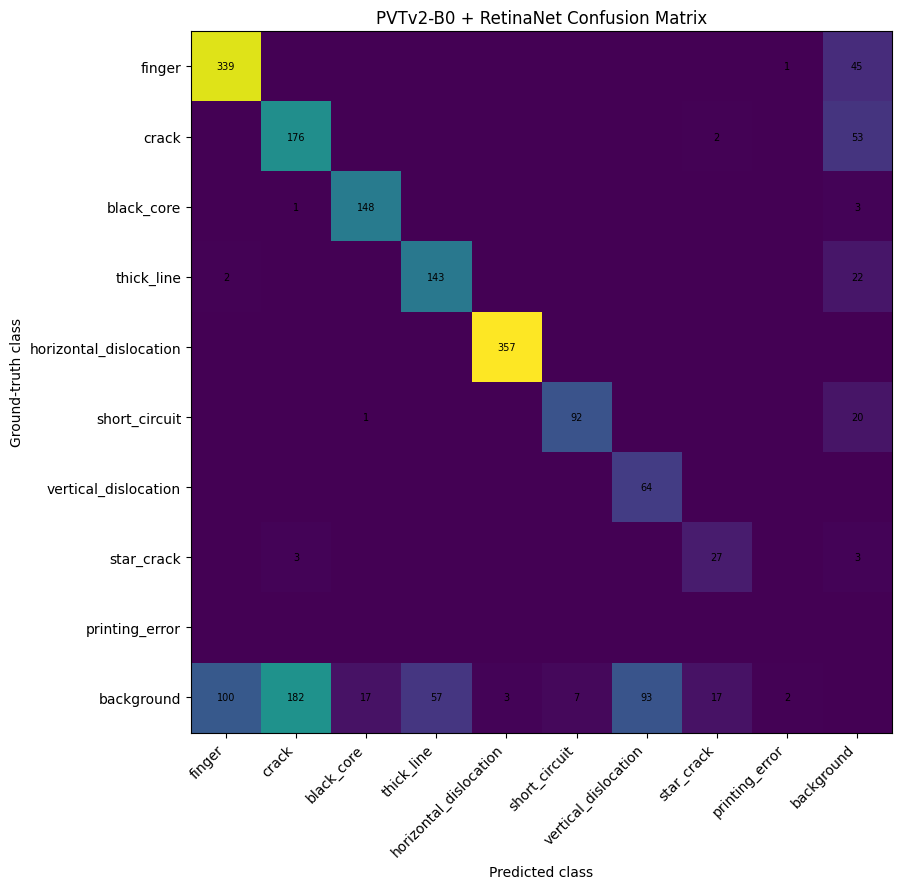

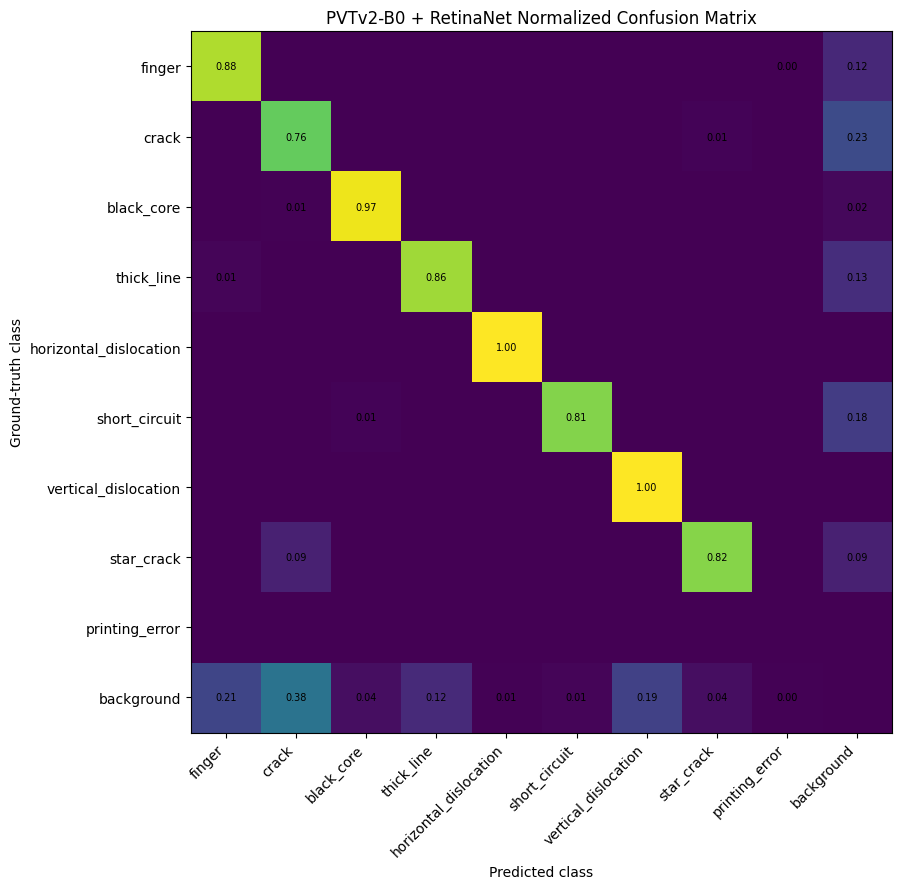

In [22]:
N = NUM_CLASSES
BG = N

confusion = np.zeros(
    (N + 1, N + 1),
    dtype=np.int64,
)

for pred, gt in zip(
    test_predictions,
    test_targets,
):
    keep = (
        pred["scores"]
        >= CONF_THRESHOLD
    )

    p_boxes = pred["boxes"][keep]
    p_labels = pred["labels"][keep]

    g_boxes = gt["boxes"]
    g_labels = gt["labels"]

    used_p = set()
    used_g = set()

    if (
        len(p_boxes)
        and len(g_boxes)
    ):
        ious = box_iou(
            p_boxes,
            g_boxes,
        )

        candidates = []

        for pi in range(
            len(p_boxes)
        ):
            for gi in range(
                len(g_boxes)
            ):
                iou = float(
                    ious[pi, gi]
                )

                if (
                    iou
                    >= MATCH_IOU_THRESHOLD
                ):
                    candidates.append(
                        (
                            iou,
                            pi,
                            gi,
                        )
                    )

        candidates.sort(
            reverse=True
        )

        for (
            iou,
            pi,
            gi,
        ) in candidates:
            if (
                pi in used_p
                or gi in used_g
            ):
                continue

            used_p.add(pi)
            used_g.add(gi)

            confusion[
                int(g_labels[gi]),
                int(p_labels[pi]),
            ] += 1

    for gi, cls_id in enumerate(
        g_labels.tolist()
    ):
        if gi not in used_g:
            confusion[
                int(cls_id),
                BG,
            ] += 1

    for pi, cls_id in enumerate(
        p_labels.tolist()
    ):
        if pi not in used_p:
            confusion[
                BG,
                int(cls_id),
            ] += 1


labels_cm = (
    CLASS_NAMES
    + ["background"]
)

row_sums = confusion.sum(
    axis=1,
    keepdims=True,
)

normalized = np.divide(
    confusion,
    row_sums,
    out=np.zeros_like(
        confusion,
        dtype=float,
    ),
    where=row_sums != 0,
)

pd.DataFrame(
    confusion,
    index=labels_cm,
    columns=labels_cm,
).to_csv(
    METRICS_DIR
    / "confusion_matrix.csv"
)

pd.DataFrame(
    normalized,
    index=labels_cm,
    columns=labels_cm,
).to_csv(
    METRICS_DIR
    / "confusion_matrix_normalized.csv"
)


def plot_confusion(
    matrix,
    title,
    filename,
    fmt,
):
    fig, ax = plt.subplots(
        figsize=(11, 9)
    )

    ax.imshow(matrix)

    ax.set_xticks(
        range(len(labels_cm))
    )

    ax.set_yticks(
        range(len(labels_cm))
    )

    ax.set_xticklabels(
        labels_cm,
        rotation=45,
        ha="right",
    )

    ax.set_yticklabels(
        labels_cm
    )

    ax.set_xlabel(
        "Predicted class"
    )

    ax.set_ylabel(
        "Ground-truth class"
    )

    ax.set_title(title)

    for i in range(
        matrix.shape[0]
    ):
        for j in range(
            matrix.shape[1]
        ):
            value = matrix[i, j]

            text = (
                f"{value:.2f}"
                if fmt == "float"
                else str(int(value))
            )

            if value != 0:
                ax.text(
                    j,
                    i,
                    text,
                    ha="center",
                    va="center",
                    fontsize=7,
                )

    plt.tight_layout()

    plt.savefig(
        PLOTS_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


plot_confusion(
    confusion,
    "PVTv2-B0 + RetinaNet Confusion Matrix",
    "confusion_matrix.png",
    "int",
)

plot_confusion(
    normalized,
    "PVTv2-B0 + RetinaNet Normalized Confusion Matrix",
    "confusion_matrix_normalized.png",
    "float",
)

## 23. Ground Truth vs Prediction

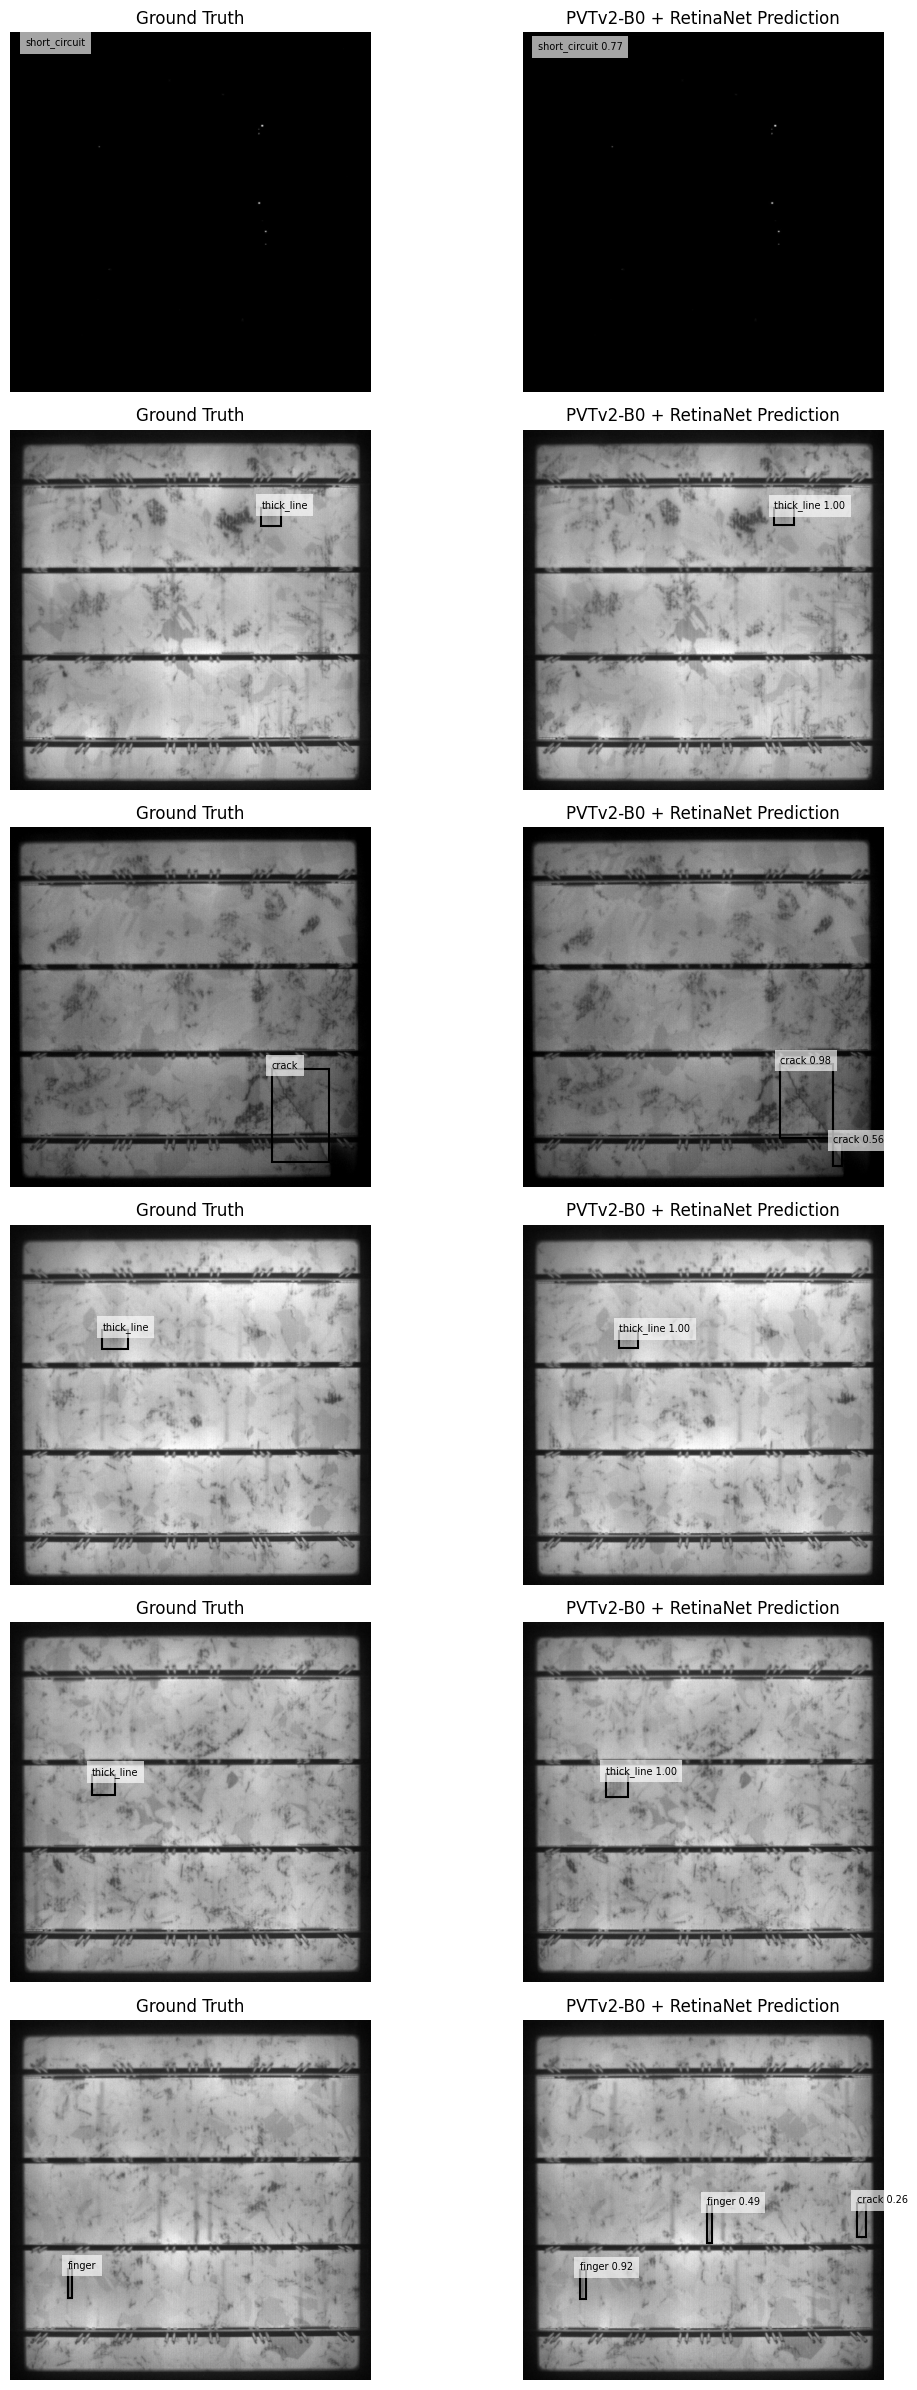

In [23]:
from matplotlib.patches import Rectangle

def show_box(
    ax,
    box,
    label,
    linewidth=1.5,
):
    x1, y1, x2, y2 = box

    rect = Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=linewidth,
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        max(10, y1),
        label,
        fontsize=7,
        bbox=dict(
            facecolor="white",
            alpha=0.65,
            edgecolor="none",
        ),
    )


defect_indices = [
    i
    for i, target
    in enumerate(test_targets)
    if len(target["boxes"]) > 0
]

random.seed(SEED)

sample_indices = random.sample(
    defect_indices,
    min(
        6,
        len(defect_indices),
    ),
)

fig, axes = plt.subplots(
    len(sample_indices),
    2,
    figsize=(
        12,
        4 * len(sample_indices),
    ),
)

if len(sample_indices) == 1:
    axes = np.array([axes])

for row, idx in enumerate(
    sample_indices
):
    image_tensor, gt, _ = (
        test_dataset[idx]
    )

    image_np = (
        image_tensor
        .permute(1, 2, 0)
        .numpy()
        .clip(0, 1)
    )

    pred = test_predictions[idx]

    axes[row, 0].imshow(
        image_np
    )

    for box, cls_id in zip(
        gt["boxes"].numpy(),
        gt["labels"].numpy(),
    ):
        show_box(
            axes[row, 0],
            box,
            CLASS_NAMES[
                int(cls_id)
            ],
        )

    axes[row, 0].set_title(
        "Ground Truth"
    )

    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        image_np
    )

    keep = (
        pred["scores"]
        >= CONF_THRESHOLD
    )

    for (
        box,
        cls_id,
        score,
    ) in zip(
        pred["boxes"][keep].numpy(),
        pred["labels"][keep].numpy(),
        pred["scores"][keep].numpy(),
    ):
        show_box(
            axes[row, 1],
            box,
            (
                f"{CLASS_NAMES[int(cls_id)]} "
                f"{score:.2f}"
            ),
        )

    axes[row, 1].set_title(
        "PVTv2-B0 + RetinaNet Prediction"
    )

    axes[row, 1].axis("off")

plt.tight_layout()

plt.savefig(
    PLOTS_DIR
    / "ground_truth_vs_prediction.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

## 24. Model complexity

In [24]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

model_size_mb = (
    BEST_PT.stat().st_size
    / 1024**2
    if BEST_PT.exists()
    else np.nan
)

model_info_df = pd.DataFrame([{
    "model":
        "PVTv2-B0 + FPN + RetinaNet",

    "parameters":
        total_params,

    "parameters_M":
        total_params / 1e6,

    "trainable_parameters":
        trainable_params,

    "trainable_parameters_M":
        trainable_params / 1e6,

    "best_checkpoint_size_MB":
        model_size_mb,
}]).round(4)

model_info_df.to_csv(
    METRICS_DIR
    / "model_info.csv",
    index=False,
)

display(model_info_df)

,model,parameters,parameters_M,trainable_parameters,trainable_parameters_M,best_checkpoint_size_MB
0,PVTv2-B0 + FPN + RetinaNet,11474133,11.4741,11474133,11.4741,43.8226


# 25. Final model summary

This only summarizes values already calculated above.  
It does **not** retrain or re-run the test set.

In [25]:
history_df = pd.read_csv(
    METRICS_DIR
    / "training_history.csv"
)

epochs_completed = int(
    history_df["epoch"].max()
)

best_epoch = int(
    history_df.loc[
        history_df[
            "val/mAP50-95"
        ].idxmax(),
        "epoch",
    ]
)

early_stopped = (
    epochs_completed
    < MAX_EPOCHS
)

final_summary_df = pd.DataFrame([{
    "Model":
        "PVTv2-B0 + FPN + RetinaNet",

    "Experiment":
        "NoAug",

    "Epochs Completed":
        epochs_completed,

    "Best Epoch":
        best_epoch,

    "Early Stopped":
        early_stopped,

    "Precision":
        test_precision,

    "Recall":
        test_recall,

    "F1":
        test_f1,

    "mAP@50":
        test_map50,

    "mAP@75":
        test_map75,

    "mAP@50-95":
        test_map50_95,

    "Mean Box IoU":
        mean_iou,

    "Mean Box Dice":
        mean_dice,

    "Matched Boxes":
        len(matched_ious),

    "Parameters (M)":
        total_params / 1e6,

    "Trainable Parameters (M)":
        trainable_params / 1e6,

    "Model Size (MB)":
        model_size_mb,

    "Physical Batch":
        BATCH_SIZE,

    "Gradient Accumulation":
        ACCUM_STEPS,

    "Effective Batch":
        EFFECTIVE_BATCH,

    "Mean Train Time/Epoch (min)":
        history_df[
            "train_seconds"
        ].mean() / 60,

    "Mean Val-Loss Time/Epoch (min)":
        history_df[
            "val_loss_seconds"
        ].mean() / 60,

    "Mean Val-mAP Time/Epoch (min)":
        history_df[
            "val_map_seconds"
        ].mean() / 60,

    "Mean Total Time/Epoch (min)":
        history_df[
            "total_seconds"
        ].mean() / 60,

    "Total Training Run Time (min)":
        history_df[
            "total_seconds"
        ].sum() / 60,

    "Peak VRAM (GB)":
        history_df[
            "peak_vram_GB"
        ].max(),

    "Inference (ms/image)":
        inference_ms,

    "FPS":
        fps,
}]).round(4)

print("=" * 78)

print(
    "PVTv2-B0 + RETINANET "
    "NO-AUGMENTATION — FINAL MODEL SUMMARY"
)

print("=" * 78)

display(final_summary_df)

print(
    "\nPER-CLASS TEST PERFORMANCE"
)

display(per_class_df)

final_summary_df.to_csv(
    METRICS_DIR
    / "final_model_summary.csv",
    index=False,
)

print("\nSaved:")

print(
    METRICS_DIR
    / "final_model_summary.csv"
)

print(
    METRICS_DIR
    / "final_per_class_summary.csv"
)

PVTv2-B0 + RETINANET NO-AUGMENTATION — FINAL MODEL SUMMARY


,Model,Experiment,Epochs Completed,Best Epoch,Early Stopped,Precision,Recall,F1,mAP@50,mAP@75,...,Gradient Accumulation,Effective Batch,Mean Train Time/Epoch (min),Mean Val-Loss Time/Epoch (min),Mean Val-mAP Time/Epoch (min),Mean Total Time/Epoch (min),Total Training Run Time (min),Peak VRAM (GB),Inference (ms/image),FPS
0,PVTv2-B0 + FPN + RetinaNet,NoAug,26,21,True,0.7366,0.8995,0.81,0.8852,0.5471,...,2,16,2.9449,0.3116,0.4054,3.662,95.2107,2.4424,26.2314,38.1223



PER-CLASS TEST PERFORMANCE


,Class,Images,Instances,Box-P,Box-R,Box-F1,mAP50,mAP50-95,Mean Box IoU,Mean Box Dice
0,finger,187,385,0.7687,0.8805,0.8208,0.8698,0.3989,0.7472,0.8553
1,crack,185,231,0.4917,0.7706,0.6003,0.6830,0.3512,0.7636,0.8660
2,black_core,150,152,0.8916,0.9737,0.9308,0.9704,0.8819,0.9421,0.9702
3,thick_line,149,167,0.7200,0.8623,0.7847,0.8387,0.3936,0.7448,0.8537
4,horizontal_dislocation,119,357,0.9917,1.0000,0.9958,0.9966,0.6136,0.8249,0.9041
5,short_circuit,113,113,0.9293,0.8142,0.8679,0.9540,0.9250,0.9676,0.9835
6,vertical_dislocation,16,64,0.4076,1.0000,0.5792,0.9510,0.5502,0.7970,0.8870
7,star_crack,30,33,0.6304,0.8788,0.7342,0.8182,0.3863,0.7521,0.8585
8,printing_error,0,0,0.0000,NaN,NaN,NaN,NaN,NaN,NaN



Saved:
/content/drive/MyDrive/Study Materials /CSE465/04_PVTv2B0_RetinaNet_NoAug/metrics/final_model_summary.csv
/content/drive/MyDrive/Study Materials /CSE465/04_PVTv2B0_RetinaNet_NoAug/metrics/final_per_class_summary.csv


## Notes for fair comparison

- Same prepared train/validation/test split.
- Deterministic 640×640 letterbox preprocessing.
- No random data augmentation.
- Maximum epochs = 50.
- Early-stopping patience = 5.
- Effective batch size = 16.
- AdamW, LR `1e-4`, weight decay `0.05`.
- PVTv2-B0 uses ImageNet-pretrained backbone weights.
- FPN and RetinaNet detection layers are trained for the 9 PV-defect classes.
- RetinaNet returns at most 100 detections/image to match standard COCO-style evaluation.
- `printing_error` has no test examples in this prepared split, so test AP for that class is unavailable.